![Python Banner](../../Image/05_04_doubleML.png)


# 4.5 Dynamic Double Machine Learning

Standard DML is for a treatment that is assigned once. Many decisions repeat: a treatment at time $t$ depends on the past, the outcome is realized at the end, and the confounders move. Dynamic DML keeps machine-learning nuisances for those confounders and still estimates how treatment in each period shifts the final outcome.


## Overview

The panel for one unit is a short history of controls and treatments and a final outcome $Y$. With a linear effect of each period's treatment,

$$Y = \sum_{t=1}^{m} \theta_t T_t + \gamma^\top W + \eta.$$

Cross-fitting residualizes $Y$ and every $T_t$ on the controls. The final stage regresses the outcome residual on the treatment residuals, one coefficient per period. When the effect also depends on baseline covariates $X$,

$$\theta_t(X) = a_t + X^\top b_t,$$

the same residuals are interacted with $(1, X)$.

A policy contrast compares a baseline path (all zeros) with a target path (all ones). For a constant effect the contrast is the sum of the period coefficients. For a heterogeneous effect it is $\sum_t \hat\theta_t(X_i)$ for each unit.


## Implementation in Python

Part A builds a balanced panel in wide form (one row per unit, one column per period). Part B uses the hospital deterioration panel in `Data/hospital-deterioration-dataset`: a supervised risk model for `deterioration_next_12h`, then a three-hour dynamic fit with `nurse_alert` as the treatment. The extract is large, so the notebook keeps a patient subsample.


## Set Up


In [1]:
import subprocess
import sys
from pathlib import Path

def _repo_root() -> Path:
    here = Path.cwd().resolve()
    for cand in [here, *here.parents]:
        if (cand / "pyproject.toml").is_file() and (cand / "src" / "pycausalml").is_dir():
            return cand
    raise FileNotFoundError(
        "PyCausalML repository was not found. Run this notebook from the repository."
    )

root = _repo_root()
data_dir = root / "Data"
if not data_dir.is_dir():
    raise FileNotFoundError(
        "The Data directory was not found. It should sit next to pyproject.toml."
    )

try:
    import pycausalml  # noqa: F401
    print("PyCausalML ready.")
except ImportError:
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "-q", "-e", f"{root}[plot]"],
    )
    print("PyCausalML installed.")
print("Data directory:", data_dir)


PyCausalML ready.
Data directory: /home/zia207/Github/PyCausalML/Data


In [2]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.ensemble import (
    GradientBoostingClassifier,
    GradientBoostingRegressor,
    RandomForestClassifier,
    RandomForestRegressor,
)
from sklearn.linear_model import Lasso, LassoCV, LogisticRegression, Ridge
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    brier_score_loss,
    mean_squared_error,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

from pycausalml import (
    CausalForestDML,
    InteractiveRegressionDML,
    KernelDML,
    LinearDML,
    NonParamDML,
    PartiallyLinearDML,
    SparseLinearDML,
    explain_cate,
)
from pycausalml.interpretation import plot_cate_hist

plt.rcParams["figure.dpi"] = 110
print("Imported PyCausalML")


Imported PyCausalML


In [3]:
def cross_fit_predict(X, y, n_splits, seed, kind="ridge"):
    """Out-of-fold predictions. kind is 'ridge', 'rf', or 'gbr'."""
    pred = np.zeros(len(y), dtype=float)
    splitter = KFold(n_splits=n_splits, shuffle=True, random_state=seed)
    y = np.asarray(y, dtype=float)
    for fold, (tr, te) in enumerate(splitter.split(X)):
        model = _nuisance(kind, seed + fold)
        model.fit(X[tr], y[tr])
        pred[te] = model.predict(X[te])
    return pred


def _nuisance(kind, seed):
    if kind == "ridge":
        return Ridge(alpha=1.0)
    if kind == "lasso":
        return Lasso(alpha=0.02, max_iter=8000)
    if kind == "rf":
        return RandomForestRegressor(
            n_estimators=40, max_depth=4, min_samples_leaf=5, random_state=seed, n_jobs=1,
        )
    if kind == "gbr":
        return GradientBoostingRegressor(
            n_estimators=40, max_depth=2, learning_rate=0.08, random_state=seed,
        )
    raise ValueError(kind)


def plot_beeswarm(explanation, title, max_display=8):
    imp = explanation.importance()
    order = np.argsort(imp)[-max_display:]
    fig, ax = plt.subplots(figsize=(7.2, 0.42 * len(order) + 1.3))
    rng = np.random.default_rng(0)
    for i, j in enumerate(order):
        vals = explanation.values[:, j]
        raw = explanation.data[:, j]
        span = float(np.ptp(raw)) or 1.0
        color = (raw - np.min(raw)) / span
        jitter = rng.uniform(-0.16, 0.16, size=len(vals))
        ax.scatter(vals, np.full(len(vals), i) + jitter, c=color, cmap="coolwarm", s=18, alpha=0.9)
    ax.set_yticks(np.arange(len(order)))
    ax.set_yticklabels([explanation.feature_names[j] for j in order])
    ax.axvline(0, color="grey", lw=0.8)
    ax.set_xlabel("SHAP value")
    ax.set_title(title)
    fig.tight_layout()
    return fig


print("Helpers ready")


Helpers ready


In [4]:
def fit_dynamic(T, controls, y, X=None, kind="ridge", n_splits=2, seed=0):
    """Period-specific linear effects of the columns of T on the final outcome."""
    T = np.asarray(T, dtype=float)
    y = np.asarray(y, dtype=float)
    y_res = y - cross_fit_predict(controls, y, n_splits, seed, kind)
    t_res = np.column_stack([
        T[:, j] - cross_fit_predict(controls, T[:, j], n_splits, seed + 1 + j, kind)
        for j in range(T.shape[1])
    ])
    if X is None:
        coef, *_ = np.linalg.lstsq(t_res, y_res, rcond=None)
        return np.asarray(coef, dtype=float)
    X = np.asarray(X, dtype=float)
    phi = np.column_stack([np.ones(len(X)), X])
    design = np.column_stack([t_res[:, j:j + 1] * phi for j in range(T.shape[1])])
    beta, *_ = np.linalg.lstsq(design, y_res, rcond=None)
    return np.asarray(beta, dtype=float).reshape(T.shape[1], phi.shape[1])


def simulate_dynamic(n=900, m=4, seed=0, heterogeneous=False):
    rng = np.random.default_rng(seed)
    controls = rng.normal(size=(n, 3))
    baseline = rng.normal(size=(n, 2))
    treatment = rng.binomial(1, 0.45, size=(n, m)).astype(float)
    gamma = np.array([0.5, -0.3, 0.2])
    if not heterogeneous:
        theta = np.linspace(0.4, 1.3, m)
        outcome = treatment @ theta + controls @ gamma + rng.normal(scale=0.5, size=n)
        return treatment, controls, baseline, outcome, theta
    intercepts = np.linspace(0.3, 1.0, m)
    slopes = np.linspace(0.2, 0.7, m)
    effect = intercepts + baseline[:, 0:1] * slopes
    outcome = np.sum(treatment * effect, axis=1) + controls @ gamma + rng.normal(scale=0.5, size=n)
    return treatment, controls, baseline, outcome, intercepts, slopes


print("Dynamic DML helpers ready")


Dynamic DML helpers ready


## Part A: Dynamic DML with Synthetic Data

### Average effects

Each unit has four periods. The true period effects increase from 0.4 to 1.3. Controls $W$ confound treatment and the final outcome.


In [5]:
T, W, X, Y, theta_true = simulate_dynamic(seed=1)
coef = fit_dynamic(T, W, Y, kind="ridge", seed=1)
print("True period effects:", np.round(theta_true, 3))
print("Estimated period effects:", np.round(coef, 3))
print("True policy effect (all zeros to all ones):", round(float(theta_true.sum()), 3))
print("Estimated policy effect:", round(float(coef.sum()), 3))


True period effects: [0.4 0.7 1.  1.3]
Estimated period effects: [0.358 0.711 1.069 1.316]
True policy effect (all zeros to all ones): 3.4
Estimated policy effect: 3.454


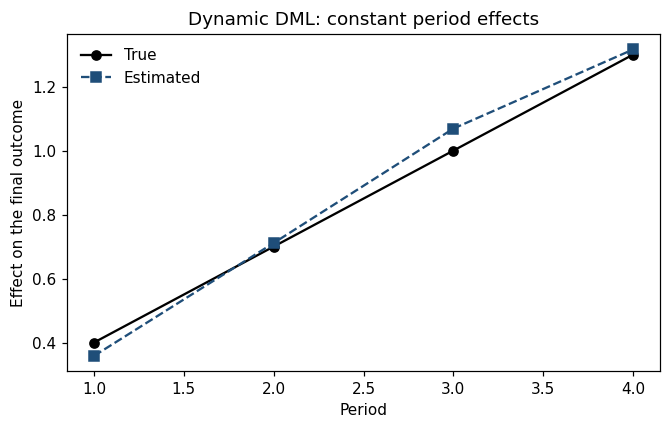

In [6]:
fig, ax = plt.subplots(figsize=(6.2, 4.0))
periods = np.arange(1, len(theta_true) + 1)
ax.plot(periods, theta_true, "o-", color="black", label="True")
ax.plot(periods, coef, "s--", color="#1F4E79", label="Estimated")
ax.set_xlabel("Period")
ax.set_ylabel("Effect on the final outcome")
ax.set_title("Dynamic DML: constant period effects")
ax.legend(frameon=False)
fig.tight_layout()


### Heterogeneous effects

Now $\theta_t(X) = a_t + b_t X_1$. The final stage is one linear model per period, with an intercept and slopes on the baseline covariates.


In [7]:
Th, Wh, Xh, Yh, a_true, b_true = simulate_dynamic(seed=2, heterogeneous=True)
betas = fit_dynamic(Th, Wh, Yh, X=Xh, kind="ridge", seed=2)
print("Intercepts, true vs estimated:")
print(np.round(np.column_stack([a_true, betas[:, 0]]), 3))
print("Slope on the first baseline covariate, true vs estimated:")
print(np.round(np.column_stack([b_true, betas[:, 1]]), 3))


Intercepts, true vs estimated:
[[0.3   0.328]
 [0.533 0.538]
 [0.767 0.787]
 [1.    0.823]]
Slope on the first baseline covariate, true vs estimated:
[[0.2   0.283]
 [0.367 0.361]
 [0.533 0.644]
 [0.7   0.75 ]]


In [8]:
rng = np.random.default_rng(3)
X_test = rng.normal(size=(400, 2))
phi = np.column_stack([np.ones(len(X_test)), X_test])
cate = phi @ betas.T
policy = cate.sum(axis=1)
print("Mean period effects on the test units:", np.round(cate.mean(axis=0), 3))
print("Mean policy effect:", round(float(policy.mean()), 3))
print("Policy effect, first five units:", np.round(policy[:5], 3))


Mean period effects on the test units: [0.33  0.531 0.784 0.821]
Mean policy effect: 2.466
Policy effect, first five units: [ 6.563  3.313  1.548 -1.646  0.808]


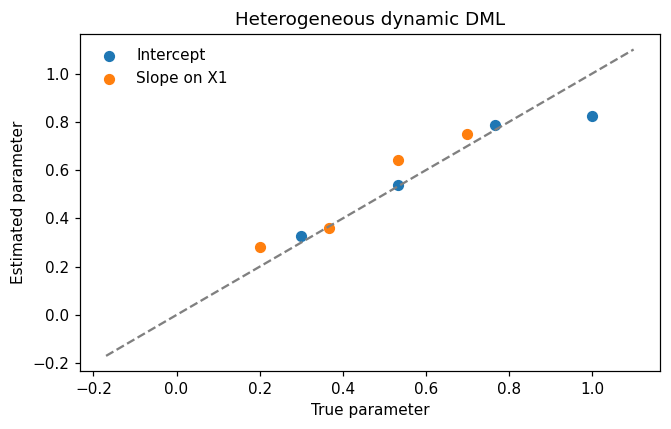

In [9]:
fig, ax = plt.subplots(figsize=(6.2, 4.0))
ax.scatter(a_true, betas[:, 0], label="Intercept", s=40)
ax.scatter(b_true, betas[:, 1], label="Slope on X1", s=40)
low = min(a_true.min(), b_true.min(), betas.min()) - 0.1
high = max(a_true.max(), b_true.max(), betas.max()) + 0.1
ax.plot([low, high], [low, high], color="grey", ls="--")
ax.set_xlabel("True parameter")
ax.set_ylabel("Estimated parameter")
ax.set_title("Heterogeneous dynamic DML")
ax.legend(frameon=False)
fig.tight_layout()


## Part B: Hospital clinical deterioration

The files in `Data/hospital-deterioration-dataset` are an hourly cohort: vitals, labs, static attributes, and `deterioration_next_12h`. This notebook reads the bundled hourly panel, keeps a random set of patients, and builds 3-hour rolling means and hour-to-hour changes on that subsample.

### Data processing


In [10]:
hospital = data_dir / "hospital-deterioration-dataset" / "hospital_deterioration_hourly_panel.csv"
usecols = [
    "patient_id", "hour_from_admission", "heart_rate", "respiratory_rate", "spo2_pct",
    "temperature_c", "systolic_bp", "diastolic_bp", "oxygen_device", "oxygen_flow",
    "mobility_score", "nurse_alert", "wbc_count", "lactate", "creatinine", "crp_level",
    "hemoglobin", "sepsis_risk_score", "age", "gender", "comorbidity_index",
    "admission_type", "deterioration_next_12h",
]
raw = pd.read_csv(hospital, usecols=usecols)
rng = np.random.default_rng(11)
patients = raw["patient_id"].drop_duplicates().to_numpy()
keep = set(rng.choice(patients, size=min(600, len(patients)), replace=False))
raw = raw[raw["patient_id"].isin(keep)].sort_values(["patient_id", "hour_from_admission"]).copy()
roll_cols = ["heart_rate", "respiratory_rate", "spo2_pct", "systolic_bp", "lactate", "creatinine"]
for col in roll_cols:
    grouped = raw.groupby("patient_id")[col]
    raw[f"{col}_roll3"] = grouped.transform(lambda s: s.rolling(3, min_periods=1).mean())
    raw[f"{col}_dh"] = grouped.diff().fillna(0.0)
print(raw.shape, "patients", raw["patient_id"].nunique())
raw.head(3)


(24571, 35) patients 600


,patient_id,hour_from_admission,heart_rate,respiratory_rate,spo2_pct,temperature_c,systolic_bp,diastolic_bp,oxygen_device,oxygen_flow,...,respiratory_rate_roll3,respiratory_rate_dh,spo2_pct_roll3,spo2_pct_dh,systolic_bp_roll3,systolic_bp_dh,lactate_roll3,lactate_dh,creatinine_roll3,creatinine_dh
142,5,0,74.61,14.91,95.61,37.23,138.78,65.30,none,0.0,...,14.91,0.00,95.610000,0.00,138.780,0.00,0.830000,0.00,0.820000,0.00
143,5,1,73.49,14.91,95.30,37.22,138.65,64.59,none,0.0,...,14.91,0.00,95.455000,-0.31,138.715,-0.13,0.885000,0.11,0.805000,-0.03
144,5,2,77.18,14.40,95.18,37.30,137.08,65.59,none,0.0,...,14.74,-0.51,95.363333,-0.12,138.170,-1.57,0.886667,-0.05,0.793333,-0.02


In [11]:
features = [
    "hour_from_admission", "heart_rate", "respiratory_rate", "spo2_pct", "temperature_c",
    "systolic_bp", "diastolic_bp", "oxygen_flow", "mobility_score", "wbc_count", "lactate",
    "creatinine", "crp_level", "hemoglobin", "sepsis_risk_score", "age", "comorbidity_index",
] + [f"{c}_roll3" for c in roll_cols] + [f"{c}_dh" for c in roll_cols]
encoded = pd.get_dummies(raw[["oxygen_device", "gender", "admission_type"]], drop_first=True)
work = pd.concat([raw.reset_index(drop=True), encoded.reset_index(drop=True)], axis=1)
feature_names = features + list(encoded.columns)
work[feature_names] = work[feature_names].apply(pd.to_numeric, errors="coerce").fillna(0.0)
print("Feature count", len(feature_names))


Feature count 36


### Train / test split and the supervised risk model


Test rows 6175
Test ROC AUC 0.901
Test average precision 0.543


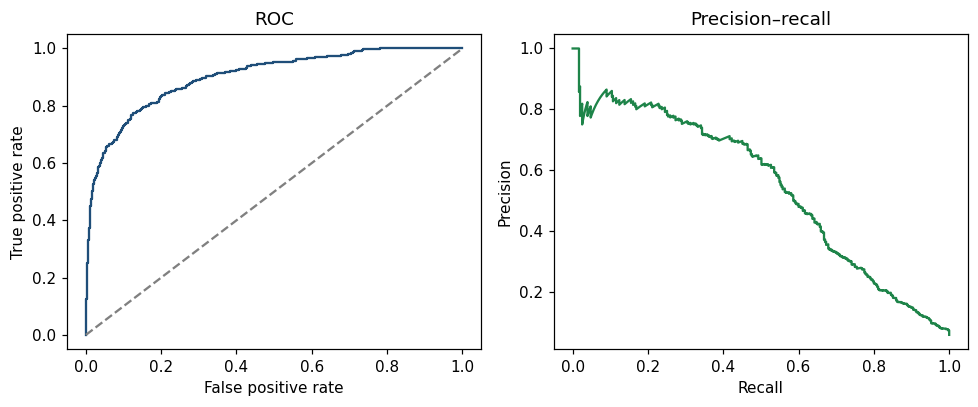

In [12]:
ids = work["patient_id"].drop_duplicates().to_numpy()
rng = np.random.default_rng(12)
test_ids = set(rng.choice(ids, size=max(1, int(0.25 * len(ids))), replace=False))
test_mask = work["patient_id"].isin(test_ids).to_numpy()
y_risk = work["deterioration_next_12h"].to_numpy(dtype=int)
X_all = work[feature_names].to_numpy(dtype=float)
clf = RandomForestClassifier(n_estimators=50, max_depth=6, min_samples_leaf=8, random_state=13, n_jobs=1)
clf.fit(X_all[~test_mask], y_risk[~test_mask])
proba = clf.predict_proba(X_all[test_mask])[:, 1]
print("Test rows", int(test_mask.sum()))
print("Test ROC AUC", round(float(roc_auc_score(y_risk[test_mask], proba)), 3))
print("Test average precision", round(float(average_precision_score(y_risk[test_mask], proba)), 3))
fpr, tpr, _ = roc_curve(y_risk[test_mask], proba)
prec, rec, thr = precision_recall_curve(y_risk[test_mask], proba)
fig, axes = plt.subplots(1, 2, figsize=(9.0, 3.8))
axes[0].plot(fpr, tpr, color="#1F4E79")
axes[0].plot([0, 1], [0, 1], color="grey", ls="--")
axes[0].set_title("ROC")
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate")
axes[1].plot(rec, prec, color="#1E8449")
axes[1].set_title("Precision–recall")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
fig.tight_layout()


### Dynamic double ML

Patients with hours 0, 1, and 2 contribute one row. Treatment is `nurse_alert` in each hour. The outcome is deterioration at hour 2. Controls are the hour-0 vitals and labs. Effect modifiers are age and the comorbidity index.


In [13]:
early = work[work["hour_from_admission"].isin([0, 1, 2])].copy()
counts = early.groupby("patient_id")["hour_from_admission"].nunique()
complete = counts[counts == 3].index
early = early[early["patient_id"].isin(complete)]
base = early[early["hour_from_admission"] == 0].set_index("patient_id")
alerts = early.pivot(index="patient_id", columns="hour_from_admission", values="nurse_alert").loc[base.index]
outcome = early[early["hour_from_admission"] == 2].set_index("patient_id").loc[base.index, "deterioration_next_12h"]
ctrl_cols = ["heart_rate", "respiratory_rate", "spo2_pct", "systolic_bp", "lactate", "creatinine", "wbc_count"]
controls = base[ctrl_cols].to_numpy(dtype=float)
modifiers = base[["age", "comorbidity_index"]].to_numpy(dtype=float)
treatment = alerts[[0, 1, 2]].to_numpy(dtype=float)
print("Patients in the three-hour panel:", len(base))
betas = fit_dynamic(treatment, controls, outcome.to_numpy(dtype=float), X=modifiers, kind="ridge", seed=15)
print("Period models, columns are intercept, age, comorbidity:")
print(np.round(betas, 4))
phi = np.column_stack([np.ones(len(modifiers)), modifiers])
policy = (phi @ betas.T).sum(axis=1)
print("Mean effect of alerting in all three hours:", round(float(policy.mean()), 4))


Patients in the three-hour panel: 600
Period models, columns are intercept, age, comorbidity:
[[-0.1635  0.0028  0.0025]
 [-0.0584  0.0015 -0.0011]
 [ 0.0442  0.0008 -0.0205]]
Mean effect of alerting in all three hours: 0.0232


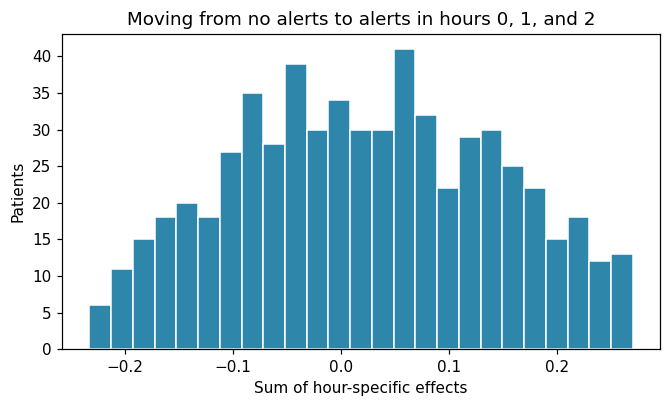

In [14]:
fig, ax = plt.subplots(figsize=(6.2, 3.8))
ax.hist(policy, bins=25, color="#2E86AB", edgecolor="white")
ax.set_xlabel("Sum of hour-specific effects")
ax.set_ylabel("Patients")
ax.set_title("Moving from no alerts to alerts in hours 0, 1, and 2")
fig.tight_layout()


In [15]:
f1 = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-8, None)
best = int(np.nanargmax(f1))
print("Best F1", round(float(f1[best]), 3), "at threshold", round(float(thr[best]), 3))
print("Test alert rate", round(float(np.mean(proba >= thr[best])), 3))
print("Precision", round(float(prec[best]), 3), "Recall", round(float(rec[best]), 3))


Best F1 0.57 at threshold 0.246
Test alert rate 0.051
Precision 0.609 Recall 0.535


### SHAP

`LinearDML` explains the hour-0 alert on the hour-2 outcome, with age and comorbidity as covariates. That is one period of the panel, which a CATE explainer can score. The coefficient table above is the multi-period summary.


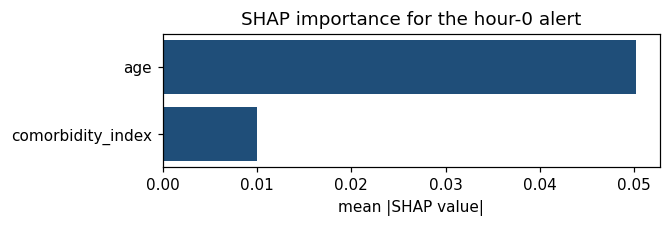

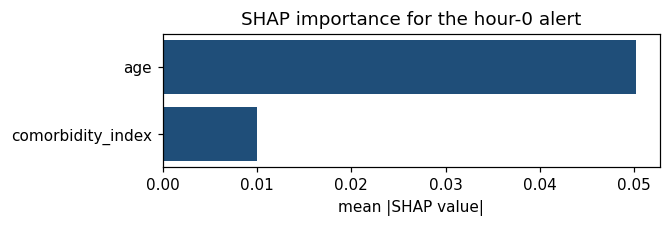

In [16]:
alert0 = alerts[0].to_numpy(dtype=float)
ldml = LinearDML(discrete_treatment=True, n_splits=2, model_y="ridge", random_state=16)
ldml.fit(modifiers, alert0, outcome.to_numpy(dtype=float), feature_names=["age", "comorbidity_index"])
explanation = explain_cate(
    ldml, modifiers, feature_names=["age", "comorbidity_index"],
    max_samples=36, n_permutations=6, random_state=16,
)
explanation.plot_importance(title="SHAP importance for the hour-0 alert")


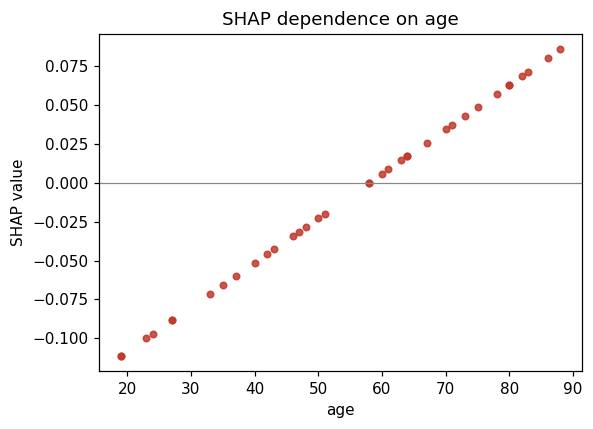

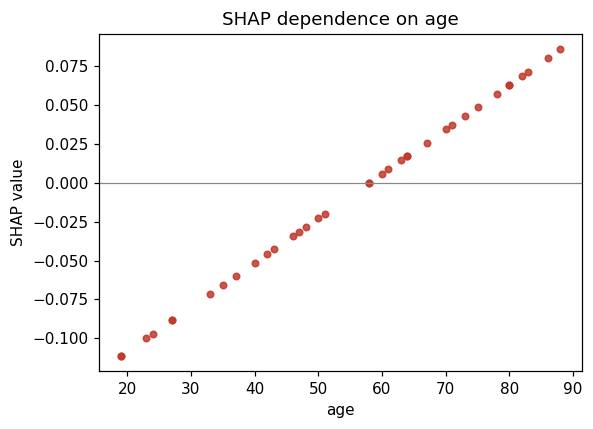

In [17]:
explanation.plot_dependence("age", title="SHAP dependence on age")


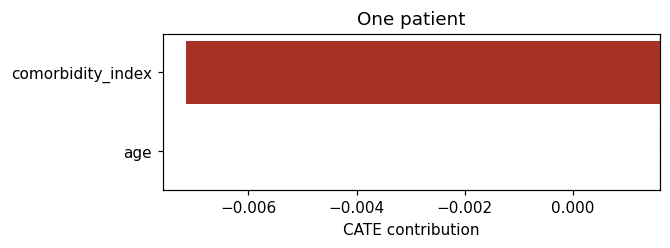

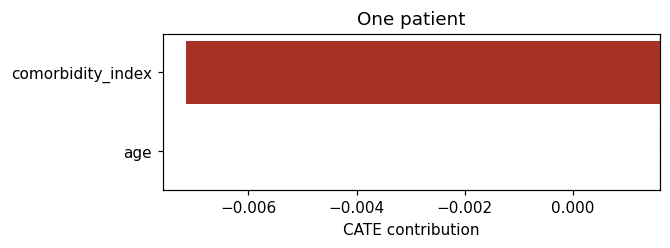

In [18]:
explanation.plot_waterfall(row=0, title="One patient")


## Summary

| Piece | Role |
|---|---|
| Wide panel | One row per unit, one treatment column per period |
| Constant dynamic DML | Residual-on-residual regression, one coefficient per period |
| Heterogeneous dynamic DML | Those residuals interacted with baseline $X$ |
| Policy contrast | All-zero path versus all-one path |
| Hospital panel | Subsample of the hourly deterioration file |
| Risk model | Random forest for the 12-hour label, separate from the causal fit |

## Resources

- Lewis, G., & Syrgkanis, V. Double/debiased machine learning for dynamic treatment effects.
- Chernozhukov, V., et al. (2018). Double/debiased machine learning for treatment and structural parameters. *The Econometrics Journal*, 21(1), C1–C68.
- The hourly cohort is `Data/hospital-deterioration-dataset`.
